<a href="https://colab.research.google.com/github/bagelleader/Fishing_Anomalies/blob/main/LICENTAFRFR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mount Drive


In [ ]:
import subprocess
from google.colab import drive
subprocess.run(['fusermount', '-u', '/content/drive'], capture_output=True)
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


Importuri si configurari

In [ ]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
import zipfile
import joblib
import tensorflow as tf
!pip install contextily -q

from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, RocCurveDisplay
from sklearn.utils import resample
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

PROJECT_DIR = "/content/drive/MyDrive/Licenta_IUU"
DATA_DIR = f"{PROJECT_DIR}/Data"
RESULTS_DIR = f"{PROJECT_DIR}/Results"

os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
print("TensorFlow version:", tf.__version__)
print("Setup complet!")

TensorFlow version: 2.20.0
Setup complet!


Data loading si curatare

In [ ]:
csv_path = f"{DATA_DIR}/LicentaIUU_clean.csv"
df = pd.read_csv(csv_path)

df = df.loc[:, ~df.columns.str.contains('^Unnamed')]
df['t'] = pd.to_datetime(df['t'])
df['label'] = df['label'].astype(int)
df = df.drop_duplicates()
df = df[df['time_gap'] <= 3600]

counts = df.groupby('id').size()
valid_ids = counts[counts >= 10].index
df = df[df['id'].isin(valid_ids)]

print("Shape final:", df.shape)
print("Nave unice:", df['id'].nunique())
print("Distributia labelurilor:\n", df['label'].value_counts())

Shape final: (1026257, 13)
Nave unice: 123
Distributia labelurilor:
 label
1    775499
0    250758
Name: count, dtype: int64


EDA

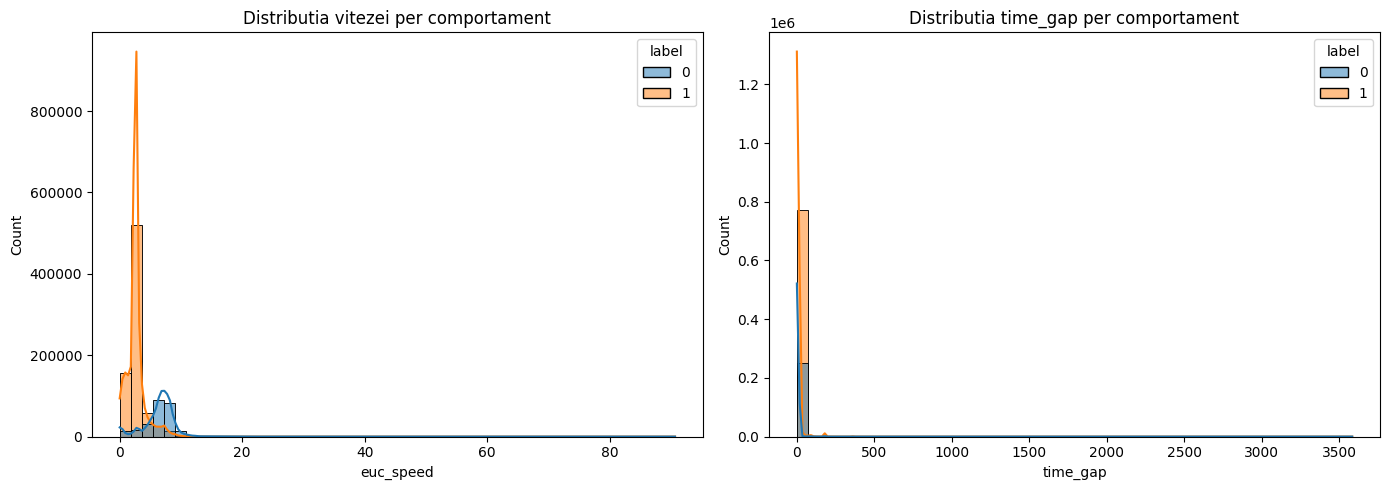

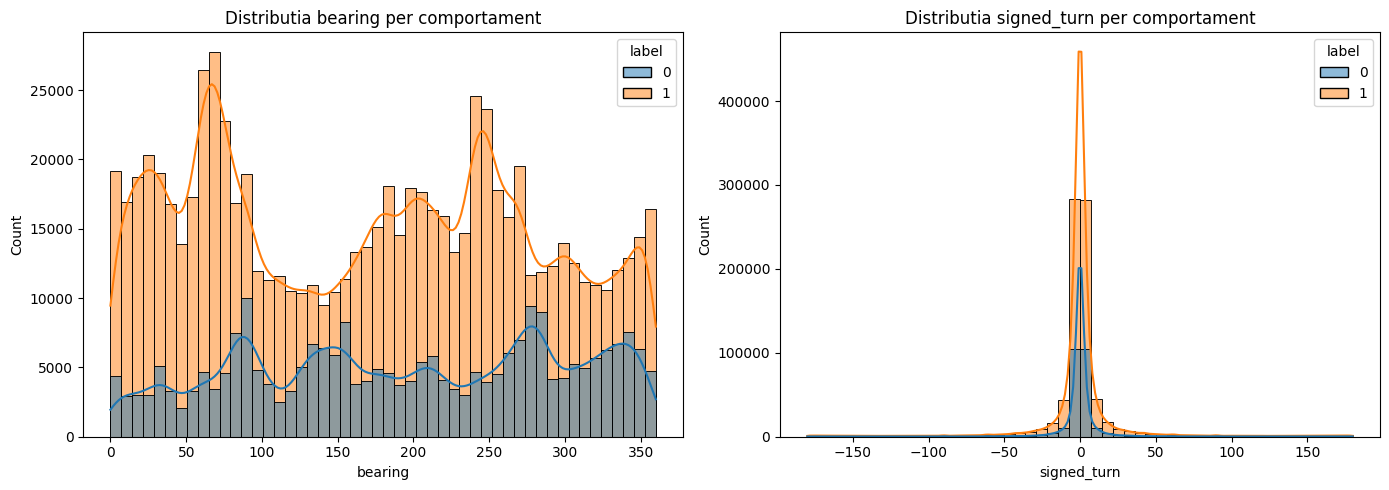

       euc_speed  time_gap  bearing  signed_turn  distance_gap  \
label                                                            
0          6.478     9.162  193.499        0.016        29.552   
1          2.653    10.912  170.354        0.187        14.600   

       distanceToShore  
label                   
0            12975.212  
1            26745.226  


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=df, x='euc_speed', hue='label', bins=50, ax=axes[0], kde=True)
axes[0].set_title('Distributia vitezei per comportament')
sns.histplot(data=df, x='time_gap', hue='label', bins=50, ax=axes[1], kde=True)
axes[1].set_title('Distributia time_gap per comportament')
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/eda_speed_timegap.png", dpi=150)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=df, x='bearing', hue='label', bins=50, ax=axes[0], kde=True)
axes[0].set_title('Distributia bearing per comportament')
sns.histplot(data=df, x='signed_turn', hue='label', bins=50, ax=axes[1], kde=True)
axes[1].set_title('Distributia signed_turn per comportament')
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/eda_bearing_turn.png", dpi=150)
plt.show()

print(df.groupby('label')[['euc_speed', 'time_gap', 'bearing', 'signed_turn', 'distance_gap', 'distanceToShore']].mean().round(3))

Feature engineering

In [ ]:
df = df.sort_values(['id', 't'])

df['speed_rolling_mean'] = df.groupby('id')['euc_speed'].transform(lambda x: x.rolling(5, min_periods=1).mean())
df['speed_rolling_std'] = df.groupby('id')['euc_speed'].transform(lambda x: x.rolling(5, min_periods=1).std().fillna(0))
df['turn_rolling_mean'] = df.groupby('id')['signed_turn'].transform(lambda x: x.rolling(5, min_periods=1).mean())
df['turn_rolling_std'] = df.groupby('id')['signed_turn'].transform(lambda x: x.rolling(5, min_periods=1).std().fillna(0))
df['speed_rolling_mean_20'] = df.groupby('id')['euc_speed'].transform(lambda x: x.rolling(20, min_periods=1).mean())
df['speed_rolling_std_20'] = df.groupby('id')['euc_speed'].transform(lambda x: x.rolling(20, min_periods=1).std().fillna(0))
df['acceleration'] = df.groupby('id')['euc_speed'].transform(lambda x: x.diff().fillna(0))
df['bearing_change'] = df.groupby('id')['bearing'].transform(lambda x: x.diff().abs().fillna(0))
df['hour'] = df['t'].dt.hour
df['month'] = df['t'].dt.month
df['is_night'] = ((df['hour'] >= 22) | (df['hour'] <= 6)).astype(int)

print("Shape:", df.shape)

Shape: (1026257, 24)


Pregatire ML

In [ ]:
FEATURES = [
    'euc_speed', 'signed_turn', 'bearing', 'distance_gap',
    'distanceToShore', 'time_gap',
    'speed_rolling_mean', 'speed_rolling_std',
    'turn_rolling_mean', 'turn_rolling_std',
    'speed_rolling_mean_20', 'speed_rolling_std_20',
    'acceleration', 'bearing_change',
    'hour', 'month', 'is_night'
]

X = df[FEATURES]
y = df['label']
groups = df['id']
gkf = GroupKFold(n_splits=5)

print("Shape X:", X.shape)
print("Numar features:", len(FEATURES))

Shape X: (1026257, 17)
Numar features: 17


Neural Network

Split train/test/validare

In [ ]:
import numpy as np

# Split pe nave ca sa nu amestecam aceeasi nava in seturi diferite
nave_unice = df['id'].unique()
np.random.seed(RANDOM_STATE)
np.random.shuffle(nave_unice)

n_nave = len(nave_unice)
n_train = int(0.70 * n_nave)
n_val = int(0.15 * n_nave)

nave_train = nave_unice[:n_train]
nave_val = nave_unice[n_train:n_train + n_val]
nave_test = nave_unice[n_train + n_val:]

df_train = df[df['id'].isin(nave_train)]
df_val = df[df['id'].isin(nave_val)]
df_test = df[df['id'].isin(nave_test)]

print(f"Nave train: {len(nave_train)} | Puncte: {len(df_train)}")
print(f"Nave val:   {len(nave_val)} | Puncte: {len(df_val)}")
print(f"Nave test:  {len(nave_test)} | Puncte: {len(df_test)}")

X_train = df_train[FEATURES]
y_train = df_train['label']
X_val = df_val[FEATURES]
y_val = df_val['label']
X_test = df_test[FEATURES]
y_test = df_test['label']

Nave train: 86 | Puncte: 733565
Nave val:   18 | Puncte: 88894
Nave test:  19 | Puncte: 203798


Scaler

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Scaler aplicat!")
print(f"X_train shape: {X_train_scaled.shape}")
print(f"X_val shape:   {X_val_scaled.shape}")
print(f"X_test shape:  {X_test_scaled.shape}")

Scaler aplicat!
X_train shape: (733565, 17)
X_val shape:   (88894, 17)
X_test shape:  (203798, 17)


Model

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Class weights
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1]),
    y=y_train
)
class_weight_dict = {0: class_weights[0], 1: class_weights[1]}
print("Class weights:", class_weight_dict)

# Construim modelul
model = keras.Sequential([
    keras.layers.Input(shape=(17,)),
    keras.layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

# Antrenare
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    X_train_scaled, y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=1000,
    batch_size=1024,
    class_weight=class_weight_dict,
    callbacks=[early_stopping],
    verbose=1
)

print(f"Antrenare terminata! Epoci rulate: {len(history.history['loss'])}")

Class weights: {0: np.float64(2.025874210848997), 1: np.float64(0.6638405041663952)}


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │            18 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18 (72.00 B)

 Trainable params: 18 (72.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/1000
717/717 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8439 - loss: 0.3703 - val_accuracy: 0.9346 - val_loss: 0.3055
Epoch 2/1000
717/717 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9230 - loss: 0.2534 - val_accuracy: 0.9322 - val_loss: 0.2773
Epoch 3/1000
717/717 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9265 - loss: 0.2425 - val_accuracy: 0.9319 - val_loss: 0.2710
Epoch 4/1000
717/717 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9270 - loss: 0.2400 - val_accuracy: 0.9322 - val_loss: 0.2689
Epoch 5/1000
717/717 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9273 - loss: 0.2391 - val_accuracy: 0.9319 - val_loss: 0.2678
Epoch 6/1000
717/717 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9273 - loss: 0.2387 - val_accuracy: 0.9313 - val_loss: 0.2679
Epoch 7/1000
717/717 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9274 - loss: 0.2383 - val_accuracy: 0.9319 - val_loss: 0.2678
Epoch 8/1000
717/717 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9274 - loss: 0.2381 - 

Learning curve

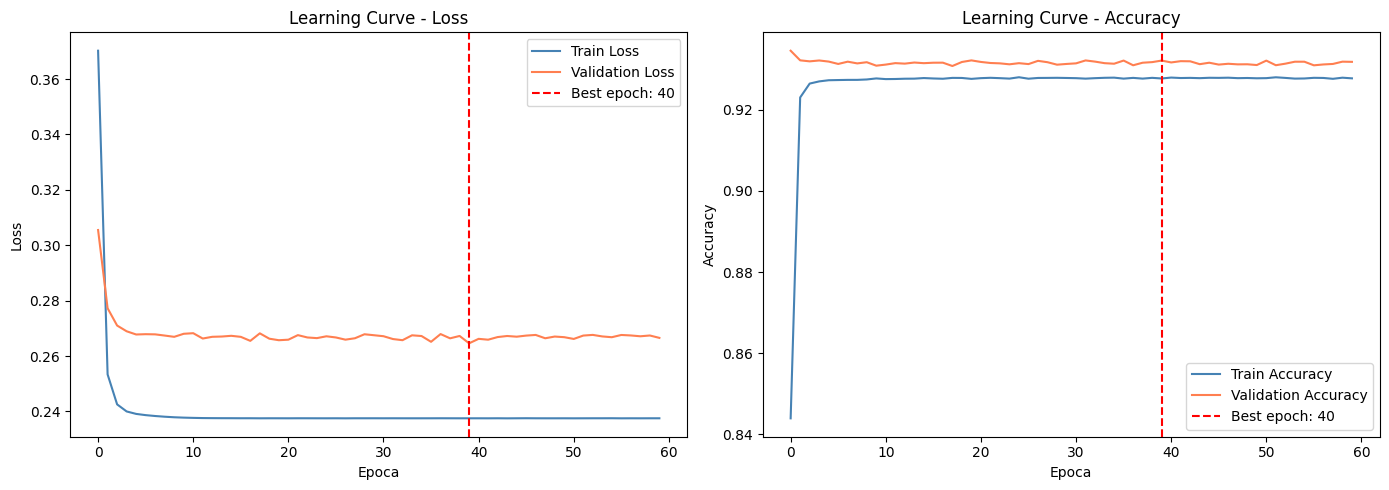

Best epoch: 40
Best val_loss: 0.2646
Best val_accuracy: 0.9321


In [ ]:
history_df = pd.DataFrame(history.history)
best_epoch = history_df['val_loss'].idxmin()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_df['loss'], label='Train Loss', color='steelblue')
axes[0].plot(history_df['val_loss'], label='Validation Loss', color='coral')
axes[0].axvline(best_epoch, color='red', linestyle='--', label=f'Best epoch: {best_epoch+1}')
axes[0].set_title('Learning Curve - Loss')
axes[0].set_xlabel('Epoca')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(history_df['accuracy'], label='Train Accuracy', color='steelblue')
axes[1].plot(history_df['val_accuracy'], label='Validation Accuracy', color='coral')
axes[1].axvline(best_epoch, color='red', linestyle='--', label=f'Best epoch: {best_epoch+1}')
axes[1].set_title('Learning Curve - Accuracy')
axes[1].set_xlabel('Epoca')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/nn_learning_curve.png", dpi=150)
plt.show()

print(f"Best epoch: {best_epoch+1}")
print(f"Best val_loss: {history_df['val_loss'].min():.4f}")
print(f"Best val_accuracy: {history_df.loc[best_epoch, 'val_accuracy']:.4f}")

Evaluare test

In [ ]:
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

y_pred_proba = model.predict(X_test_scaled).flatten()
y_pred = (y_pred_proba > 0.5).astype(int)

print("=== Evaluare pe Test Set ===")
print(classification_report(y_test, y_pred, target_names=['Sailing', 'Fishing']))
print(f"AUC: {roc_auc_score(y_test, y_pred_proba):.4f}")

6369/6369 ━━━━━━━━━━━━━━━━━━━━ 10s 1ms/step
=== Evaluare pe Test Set ===
              precision    recall  f1-score   support

     Sailing       0.69      0.71      0.70     47852
     Fishing       0.91      0.90      0.91    155946

    accuracy                           0.86    203798
   macro avg       0.80      0.81      0.80    203798
weighted avg       0.86      0.86      0.86    203798

AUC: 0.8682


Vizualizare Neural Network

6369/6369 ━━━━━━━━━━━━━━━━━━━━ 21s 3ms/step


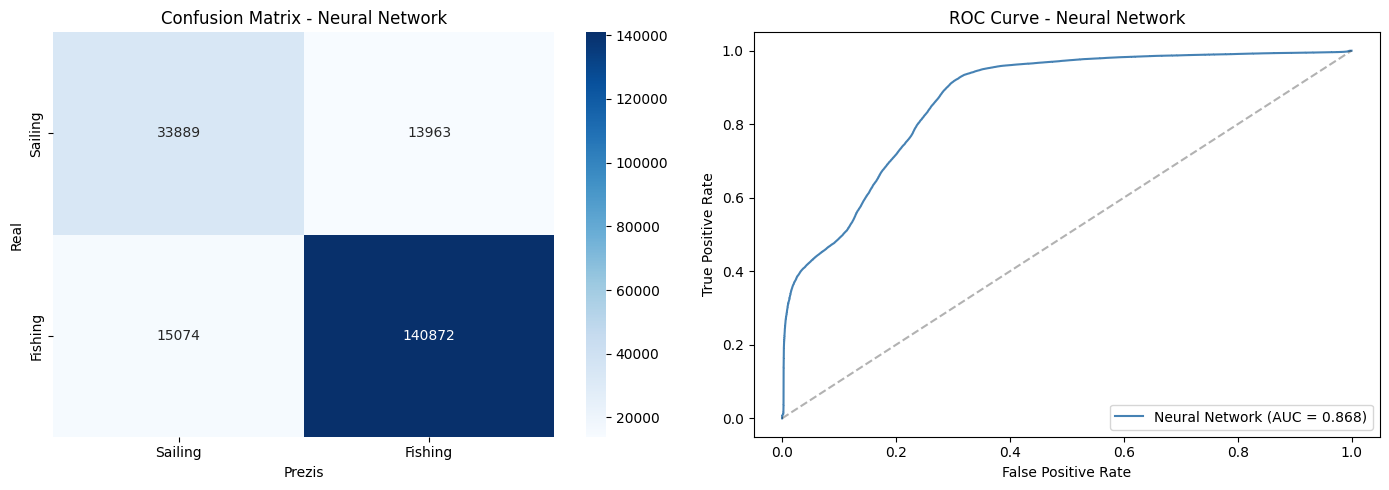

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Confusion Matrix pe test set
cm_nn = confusion_matrix(y_test, y_pred)
sns.heatmap(cm_nn, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Sailing', 'Fishing'],
            yticklabels=['Sailing', 'Fishing'])
axes[0].set_title('Confusion Matrix - Neural Network')
axes[0].set_ylabel('Real')
axes[0].set_xlabel('Prezis')

# 2. ROC Curve
from sklearn.metrics import roc_curve, auc
fpr, tpr, _ = roc_curve(y_test, model.predict(X_test_scaled).flatten())
auc_score = auc(fpr, tpr)
axes[1].plot(fpr, tpr, color='steelblue', label=f'Neural Network (AUC = {auc_score:.3f})')
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.3)
axes[1].set_title('ROC Curve - Neural Network')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend()

plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/nn_evaluare.png", dpi=150)
plt.show()

In [ ]:
model.save(f"{RESULTS_DIR}/nn_model.keras")
history_df = pd.DataFrame(history.history)
history_df.index.name = 'epoch'
history_df.to_csv(f"{RESULTS_DIR}/nn_history.csv")
joblib.dump(scaler, f"{RESULTS_DIR}/nn_scaler.pkl")

nn_metrics = {
    'accuracy': float(roc_auc_score(y_test, y_pred_proba)),
    'f1_sailing': float(classification_report(y_test, y_pred, output_dict=True)['0']['f1-score']),
    'f1_fishing': float(classification_report(y_test, y_pred, output_dict=True)['1']['f1-score']),
    'auc': float(roc_auc_score(y_test, y_pred_proba))
}

import json
with open(f"{RESULTS_DIR}/nn_metrics.json", 'w') as f:
    json.dump(nn_metrics, f)

print("Totul salvat!")
print(nn_metrics)

Totul salvat!
{'accuracy': 0.8682372342713826, 'f1_sailing': 0.7000774673346073, 'f1_fishing': 0.9065676473143468, 'auc': 0.8682372342713826}


Random forest

In [ ]:
FEATURES_RF = [
    'speed_rolling_mean',
    'speed_rolling_mean_20',
    'distanceToShore',
    'euc_speed',
    'bearing',
    'distance_gap',
    'hour',
    'speed_rolling_std_20',
    'turn_rolling_std',
    'speed_rolling_std',
    'time_gap',
    'is_night',
    'turn_rolling_mean'
]

print(f"Features selectate: {len(FEATURES_RF)}")

X_train_rf = df_train[FEATURES_RF]
y_train_rf = df_train['label']
X_val_rf = df_val[FEATURES_RF]
y_val_rf = df_val['label']
X_test_rf = df_test[FEATURES_RF]
y_test_rf = df_test['label']

# Scaler separat
scaler_rf = StandardScaler()
X_train_rf_scaled = scaler_rf.fit_transform(X_train_rf)
X_val_rf_scaled = scaler_rf.transform(X_val_rf)
X_test_rf_scaled = scaler_rf.transform(X_test_rf)

print("Scaler RF aplicat!")

Features selectate: 13
Scaler RF aplicat!


/usr/local/lib/python3.12/dist-packages/sklearn/ensemble/_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


n_trees=10 | OOB Error: 0.0300


/usr/local/lib/python3.12/dist-packages/sklearn/ensemble/_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


n_trees=20 | OOB Error: 0.0212
n_trees=30 | OOB Error: 0.0205
n_trees=40 | OOB Error: 0.0203
n_trees=50 | OOB Error: 0.0200
n_trees=60 | OOB Error: 0.0199
n_trees=70 | OOB Error: 0.0199
n_trees=80 | OOB Error: 0.0198
n_trees=90 | OOB Error: 0.0199
n_trees=100 | OOB Error: 0.0199
n_trees=110 | OOB Error: 0.0199
n_trees=120 | OOB Error: 0.0198
n_trees=130 | OOB Error: 0.0198
n_trees=140 | OOB Error: 0.0197
n_trees=150 | OOB Error: 0.0198
n_trees=160 | OOB Error: 0.0198
n_trees=170 | OOB Error: 0.0198
n_trees=180 | OOB Error: 0.0198
n_trees=190 | OOB Error: 0.0199
n_trees=200 | OOB Error: 0.0199


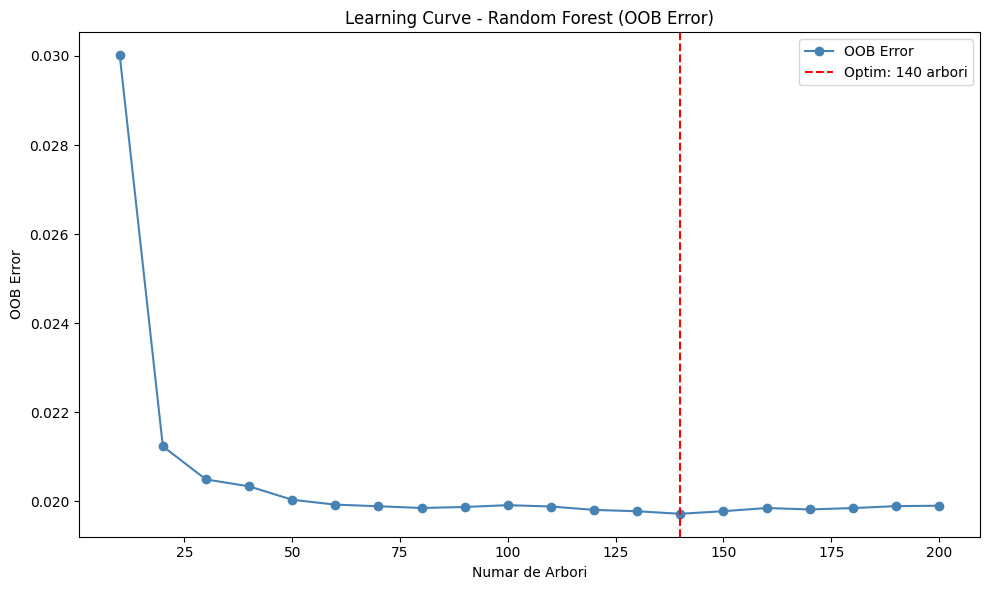


Numar optim de arbori: 140
OOB Error minim: 0.0197


In [ ]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier

oob_errors = []
n_trees_range = range(10, 201, 10)

for n_trees in n_trees_range:
    rf_temp = RandomForestClassifier(
        n_estimators=n_trees,
        min_samples_leaf=50,
        min_samples_split=200,
        class_weight='balanced',
        oob_score=True,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    rf_temp.fit(X_train_rf_scaled, y_train_rf)
    oob_errors.append(1 - rf_temp.oob_score_)
    print(f"n_trees={n_trees} | OOB Error: {1 - rf_temp.oob_score_:.4f}")

# Grafic
optimal_trees = list(n_trees_range)[np.argmin(oob_errors)]

plt.figure(figsize=(10, 6))
plt.plot(list(n_trees_range), oob_errors, marker='o', color='steelblue', label='OOB Error')
plt.axvline(optimal_trees, color='red', linestyle='--', label=f'Optim: {optimal_trees} arbori')
plt.title('Learning Curve - Random Forest (OOB Error)')
plt.xlabel('Numar de Arbori')
plt.ylabel('OOB Error')
plt.legend()
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/rf_learning_curve.png", dpi=150)
plt.show()

print(f"\nNumar optim de arbori: {optimal_trees}")
print(f"OOB Error minim: {min(oob_errors):.4f}")

RF OPTIM

In [ ]:
rf_final = RandomForestClassifier(
    n_estimators=140,
    min_samples_leaf=50,
    min_samples_split=200,
    class_weight='balanced',
    oob_score=True,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_final.fit(X_train_rf_scaled, y_train_rf)
print(f"OOB Score: {rf_final.oob_score_:.4f}")

# Evaluare pe test set
y_pred_rf_new = rf_final.predict(X_test_rf_scaled)
y_proba_rf_new = rf_final.predict_proba(X_test_rf_scaled)[:, 1]

from sklearn.metrics import classification_report, roc_auc_score
print("\n=== Evaluare pe Test Set ===")
print(classification_report(y_test_rf, y_pred_rf_new, target_names=['Sailing', 'Fishing']))
print(f"AUC: {roc_auc_score(y_test_rf, y_proba_rf_new):.4f}")

OOB Score: 0.9803

=== Evaluare pe Test Set ===
              precision    recall  f1-score   support

     Sailing       0.76      0.76      0.76     47852
     Fishing       0.93      0.93      0.93    155946

    accuracy                           0.89    203798
   macro avg       0.84      0.84      0.84    203798
weighted avg       0.89      0.89      0.89    203798

AUC: 0.8939


Vizualizare si feature importance

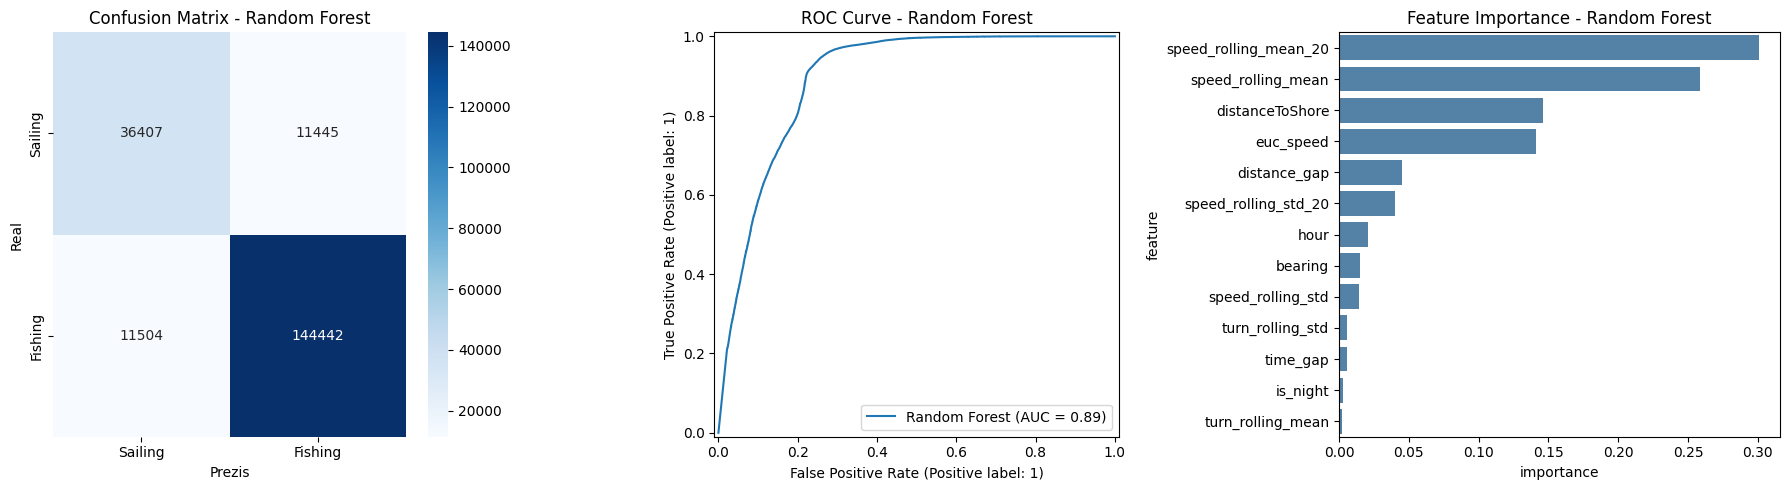

              feature  importance
speed_rolling_mean_20    0.300824
   speed_rolling_mean    0.258799
      distanceToShore    0.146214
            euc_speed    0.141151
         distance_gap    0.044907
 speed_rolling_std_20    0.040194
                 hour    0.020928
              bearing    0.015395
    speed_rolling_std    0.014228
     turn_rolling_std    0.006015
             time_gap    0.005954
             is_night    0.003064
    turn_rolling_mean    0.002325


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Confusion Matrix
cm = confusion_matrix(y_test_rf, y_pred_rf_new)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Sailing', 'Fishing'],
            yticklabels=['Sailing', 'Fishing'])
axes[0].set_title('Confusion Matrix - Random Forest')
axes[0].set_ylabel('Real')
axes[0].set_xlabel('Prezis')

# 2. ROC Curve
from sklearn.metrics import RocCurveDisplay
RocCurveDisplay.from_predictions(y_test_rf, y_proba_rf_new, ax=axes[1], name='Random Forest')
axes[1].set_title('ROC Curve - Random Forest')

# 3. Feature Importance
feat_imp_new = pd.DataFrame({
    'feature': FEATURES_RF,
    'importance': rf_final.feature_importances_
}).sort_values('importance', ascending=False)

sns.barplot(data=feat_imp_new, x='importance', y='feature', ax=axes[2], color='steelblue')
axes[2].set_title('Feature Importance - Random Forest')

plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/rf_evaluare_finala.png", dpi=150)
plt.show()

print(feat_imp_new.to_string(index=False))

Expl rf

In [ ]:
# Explainability RF - pentru navele foarte suspecte
nave_foarte_suspecte = scor_df_rf[scor_df_rf['scor_final'] >= 3]['id'].tolist()

for nava in nave_foarte_suspecte:
    puncte_nava = df[df['id'] == nava][FEATURES_RF]
    puncte_scaled = scaler_rf.transform(puncte_nava)
    predictii = rf_final.predict(puncte_scaled)

    # Media features pentru punctele clasificate ca fishing
    fishing_points = puncte_nava[predictii == 1]
    media_nava = fishing_points.mean()
    media_globala = df[FEATURES_RF].mean()

    diferenta = media_nava - media_globala

    print(f"\nNava: {nava}")
    print("Feature | Valoare nava | Medie globala | Diferenta")
    for feat in FEATURES_RF:
        print(f"{feat:25s}: {media_nava[feat]:8.3f} | {media_globala[feat]:8.3f} | {diferenta[feat]:+.3f}")


Nava: 232020276-2
Feature | Valoare nava | Medie globala | Diferenta
speed_rolling_mean       :    4.384 |    3.587 | +0.796
speed_rolling_mean_20    :    4.381 |    3.587 | +0.794
distanceToShore          : 79007.423 | 23380.629 | +55626.795
euc_speed                :    4.387 |    3.587 | +0.799
bearing                  :  129.168 |  176.009 | -46.841
distance_gap             :   55.471 |   18.253 | +37.218
hour                     :    7.602 |   11.043 | -3.441
speed_rolling_std_20     :    0.614 |    0.553 | +0.061
turn_rolling_std         :    9.833 |   12.488 | -2.655
speed_rolling_std        :    0.361 |    0.463 | -0.102
time_gap                 :   33.008 |   10.484 | +22.524
is_night                 :    0.685 |    0.355 | +0.330
turn_rolling_mean        :    0.935 |    0.144 | +0.791

Nava: 232020276-3
Feature | Valoare nava | Medie globala | Diferenta
speed_rolling_mean       :    4.784 |    3.587 | +1.197
speed_rolling_mean_20    :    4.783 |    3.587 | +1.197
distanceToS

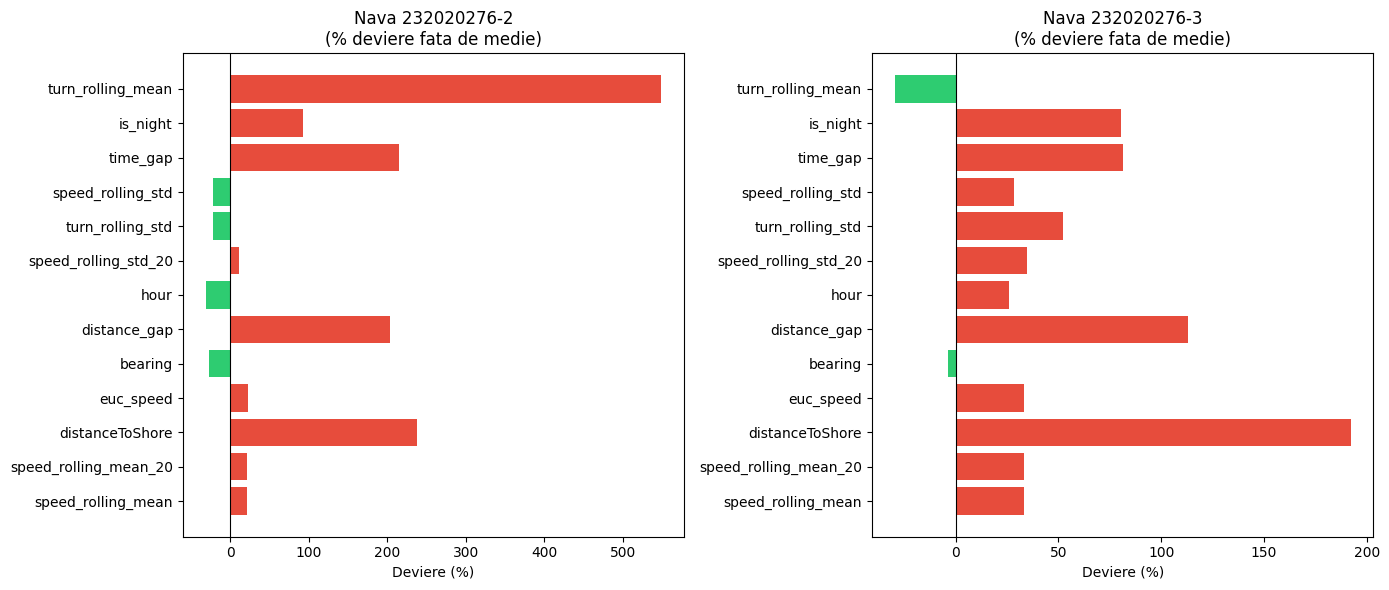

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for idx, nava in enumerate(nave_foarte_suspecte):
    puncte_nava = df[df['id'] == nava][FEATURES_RF]
    puncte_scaled = scaler_rf.transform(puncte_nava)
    predictii = rf_final.predict(puncte_scaled)
    fishing_points = puncte_nava[predictii == 1]
    media_nava = fishing_points.mean()
    media_globala = df[FEATURES_RF].mean()
    diferenta = (media_nava - media_globala) / media_globala.abs() * 100

    colors = ['#e74c3c' if v > 0 else '#2ecc71' for v in diferenta.values]
    axes[idx].barh(FEATURES_RF, diferenta.values, color=colors)
    axes[idx].axvline(0, color='black', linewidth=0.8)
    axes[idx].set_title(f'Nava {nava}\n(% deviere fata de medie)')
    axes[idx].set_xlabel('Deviere (%)')

plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/rf_explainability.png", dpi=150)
plt.show()

In [ ]:
joblib.dump(rf_final, f"{RESULTS_DIR}/rf_final.pkl")
joblib.dump(scaler_rf, f"{RESULTS_DIR}/rf_scaler.pkl")
print("Model RF salvat!")

Model RF salvat!


Analiza geospatiala

In [ ]:
zip_path = f"{DATA_DIR}/World_EEZ_v12_20231025.zip"
extract_path = f"{DATA_DIR}/EEZ_full"
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

eez = gpd.read_file(f"{extract_path}/World_EEZ_v12_20231025/eez_v12.shp")
tari_nord = ['Norway', 'Denmark', 'Sweden', 'United Kingdom',
             'Netherlands', 'Germany', 'Belgium', 'France']
eez_nord = eez[eez['SOVEREIGN1'].isin(tari_nord)].copy()
eez_nord = eez_nord.to_crs('EPSG:4326')
eez_nord = eez_nord.cx[5:15, 53:60]
print("Zone EEZ in zona de interes:", eez_nord.shape[0])
print(eez_nord[['SOVEREIGN1', 'TERRITORY1']].to_string())

Zone EEZ in zona de interes: 6
      SOVEREIGN1   TERRITORY1
210       Sweden       Sweden
212       Norway       Norway
214  Netherlands  Netherlands
215      Germany      Germany
216      Denmark      Denmark
269       Norway       Norway


Spatial Join

In [ ]:
gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df['longitude'], df['latitude']), crs='EPSG:4326')

gdf_joined = gpd.sjoin(gdf, eez_nord[['SOVEREIGN1', 'TERRITORY1', 'geometry']],
                        how='left', predicate='within')
gdf_joined['in_eez'] = gdf_joined['SOVEREIGN1'].notna()
gdf_joined['SOVEREIGN1'] = gdf_joined['SOVEREIGN1'].fillna('High Seas')

df['SOVEREIGN1'] = gdf_joined['SOVEREIGN1'].values
df['in_eez'] = gdf_joined['in_eez'].values

print(df['SOVEREIGN1'].value_counts())
print(f"Puncte in EEZ: {df['in_eez'].sum()}")
print(f"Puncte in ape internationale: {(~df['in_eez']).sum()}")

SOVEREIGN1
Denmark      926996
Sweden        53007
Norway        37472
High Seas      8782
Name: count, dtype: int64
Puncte in EEZ: 1017475
Puncte in ape internationale: 8782


Harta

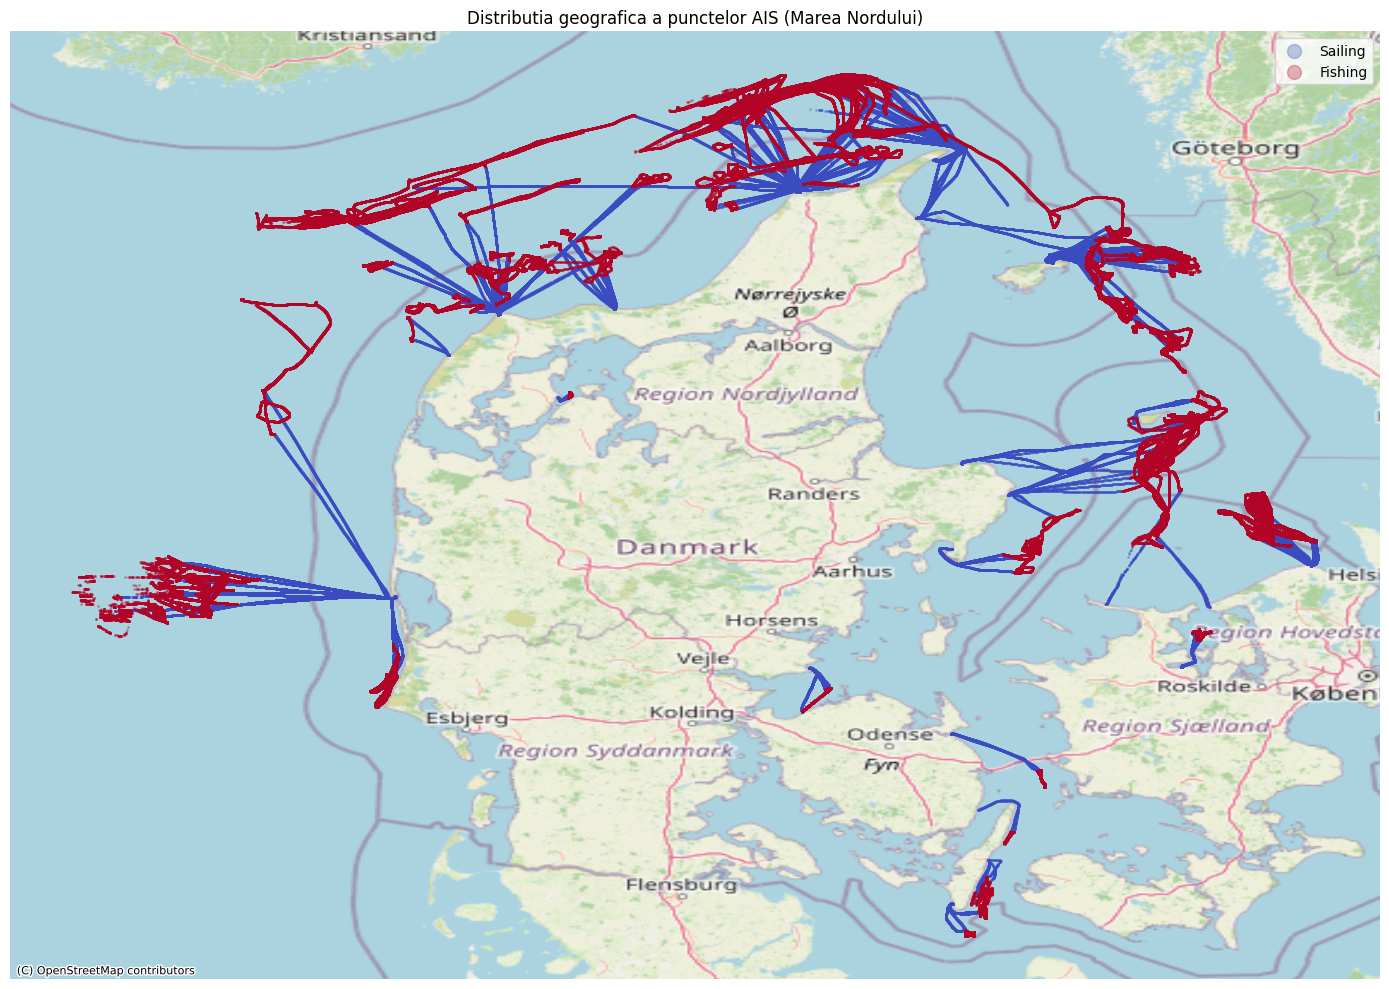

In [ ]:
import contextily as ctx
import geopandas as gpd

# Cream GeoDataFrame
gdf_map = gpd.GeoDataFrame(
    df[['longitude', 'latitude', 'label']].copy(),
    geometry=gpd.points_from_xy(df['longitude'], df['latitude']),
    crs='EPSG:4326'
).to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(14, 10))

# Sailing
sailing = gdf_map[gdf_map['label'] == 0]
ax.scatter(sailing.geometry.x, sailing.geometry.y,
           s=1, alpha=0.3, color='#3b4cc0', label='Sailing')

# Fishing
fishing = gdf_map[gdf_map['label'] == 1]
ax.scatter(fishing.geometry.x, fishing.geometry.y,
           s=1, alpha=0.3, color='#b40426', label='Fishing')

# Adaugam harta reala de fundal
ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik)

ax.set_title('Distributia geografica a punctelor AIS (Marea Nordului)')
ax.set_axis_off()
ax.legend(markerscale=10)

plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/harta_puncte_ais_real.png", dpi=150, bbox_inches='tight')
plt.show()

Detectie comportamente suspecte: Neural Network


Predictii NN

In [ ]:
X_full_scaled = scaler.transform(df[FEATURES])
df['predicted_label'] = (model.predict(X_full_scaled).flatten() > 0.5).astype(int)
df['fishing_proba'] = model.predict(X_full_scaled).flatten()

print("Predictii NN adaugate!")
print(df['predicted_label'].value_counts())

32071/32071 ━━━━━━━━━━━━━━━━━━━━ 64s 2ms/step
32071/32071 ━━━━━━━━━━━━━━━━━━━━ 49s 2ms/step
Predictii NN adaugate!
predicted_label
1    756701
0    269556
Name: count, dtype: int64


Reguli manuale

In [ ]:
#Regula 1: Loitering  sa faci cm
loitering = df[
    (df['predicted_label'] == 1) &
    (df['euc_speed'] < 0.787) &
    (df['speed_rolling_mean'] < 1.0) &
    (df['turn_rolling_std'] > 37.0)
].copy()
loitering_per_nava = loitering.groupby('id').size().sort_values(ascending=False)
nave_suspecte_loitering = loitering_per_nava[loitering_per_nava > 500].index
print(f"Nave cu loitering semnificativ: {len(nave_suspecte_loitering)}")

#Regula 2: Pescuit noaptea
pescuit_noapte = df[(df['predicted_label'] == 1) & (df['is_night'] == 1)].copy()
noapte_per_nava = pescuit_noapte.groupby('id').size()
total_fishing_per_nava = df[df['predicted_label'] == 1].groupby('id').size()
procent_noapte = (noapte_per_nava / total_fishing_per_nava * 100).dropna().sort_values(ascending=False)
nave_suspecte_noapte = procent_noapte[procent_noapte > 55].index
print(f"Nave cu pescuit nocturn >55%: {len(nave_suspecte_noapte)}")

#Regula 3: AIS Gap suspect
ais_gap = df[df['time_gap'] > 1800].copy()
gap_per_nava = ais_gap.groupby('id').size().sort_values(ascending=False)
nave_suspecte_gap = gap_per_nava[gap_per_nava >= 2].index
print(f"Nave cu AIS gap suspect: {len(nave_suspecte_gap)}")

# Regula 4: Pescuit in ape internationale
pescuit_high_seas = df[(df['predicted_label'] == 1) & (df['in_eez'] == False)].copy()
high_seas_per_nava = pescuit_high_seas.groupby('id').size().sort_values(ascending=False)
nave_suspecte_high_seas = high_seas_per_nava[high_seas_per_nava > 200].index
print(f"Nave cu pescuit in ape internationale: {len(nave_suspecte_high_seas)}")

Nave cu loitering semnificativ: 17
Nave cu pescuit nocturn >55%: 17
Nave cu AIS gap suspect: 7
Nave cu pescuit in ape internationale: 5


Isolation Forest

In [ ]:
from sklearn.ensemble import IsolationForest

nave_features = df.groupby('id').agg(
    viteza_medie=('euc_speed', 'mean'),
    viteza_std=('euc_speed', 'std'),
    turn_std=('turn_rolling_std', 'mean'),
    time_gap_max=('time_gap', 'max'),
    fishing_ratio=('predicted_label', 'mean'),
    noapte_ratio=('is_night', 'mean'),
    distanta_tarm=('distanceToShore', 'mean'),
    acceleratie_medie=('acceleration', 'mean')
).reset_index()

X_if = nave_features.drop('id', axis=1)
X_if_scaled = StandardScaler().fit_transform(X_if)

iso_forest = IsolationForest(n_estimators=100, contamination=0.1, random_state=RANDOM_STATE)
nave_features['anomalie'] = iso_forest.fit_predict(X_if_scaled)
nave_features['anomalie_scor'] = iso_forest.score_samples(X_if_scaled)

nave_anomalii_if = set(nave_features[nave_features['anomalie'] == -1]['id'])
print(f"Nave detectate ca anomalii: {len(nave_anomalii_if)}")

Nave detectate ca anomalii: 13


Scor final

In [ ]:
scor_df = pd.DataFrame({'id': df['id'].unique()})

scor_df['loitering'] = scor_df['id'].isin(nave_suspecte_loitering).astype(int)
scor_df['pescuit_noapte'] = scor_df['id'].isin(nave_suspecte_noapte).astype(int)
scor_df['ais_gap'] = scor_df['id'].isin(nave_suspecte_gap).astype(int)
scor_df['high_seas'] = scor_df['id'].isin(nave_suspecte_high_seas).astype(int)
scor_df['isolation_forest'] = scor_df['id'].isin(nave_anomalii_if).astype(int)
scor_df['scor_final'] = scor_df[['loitering', 'pescuit_noapte', 'ais_gap', 'high_seas', 'isolation_forest']].sum(axis=1)

print("Distributia scorurilor finale:")
print(scor_df['scor_final'].value_counts().sort_index())
print(f"\nNave normale (scor 0): {(scor_df['scor_final']==0).sum()}")
print(f"Nave suspecte (scor 1): {(scor_df['scor_final']==1).sum()}")
print(f"Nave suspecte (scor 2): {(scor_df['scor_final']==2).sum()}")
print(f"Nave foarte suspecte (scor 3+): {(scor_df['scor_final']>=3).sum()}")

scor_df.to_csv(f"{RESULTS_DIR}/scor_final_iuu.csv", index=False)

Distributia scorurilor finale:
scor_final
0    79
1    31
2    11
3     2
Name: count, dtype: int64

Nave normale (scor 0): 79
Nave suspecte (scor 1): 31
Nave suspecte (scor 2): 11
Nave foarte suspecte (scor 3+): 2


Detectare comportamente suspecte: Random Forest

Predictii Random Forest

In [ ]:
X_full_rf = df[FEATURES_RF]
X_full_rf_scaled = scaler_rf.transform(X_full_rf)
df['predicted_label_rf'] = rf_final.predict(X_full_rf_scaled)
df['fishing_proba_rf'] = rf_final.predict_proba(X_full_rf_scaled)[:, 1]

print("Predictii RF adaugate!")
print(df['predicted_label_rf'].value_counts())

Predictii RF adaugate!
predicted_label_rf
1    762822
0    263435
Name: count, dtype: int64


Reguli manualre Random Forest

In [ ]:
#regula 1 Loitering RF
loitering_rf = df[
    (df['predicted_label_rf'] == 1) &
    (df['euc_speed'] < 0.787) &
    (df['speed_rolling_mean'] < 1.0) &
    (df['turn_rolling_std'] > 37.0)
].copy()
loitering_per_nava_rf = loitering_rf.groupby('id').size().sort_values(ascending=False)
nave_suspecte_loitering_rf = loitering_per_nava_rf[loitering_per_nava_rf > 500].index
print(f"Nave cu loitering semnificativ: {len(nave_suspecte_loitering_rf)}")

#regula 2 Pescuit noaptea RF
pescuit_noapte_rf = df[(df['predicted_label_rf'] == 1) & (df['is_night'] == 1)].copy()
noapte_per_nava_rf = pescuit_noapte_rf.groupby('id').size()
total_fishing_per_nava_rf = df[df['predicted_label_rf'] == 1].groupby('id').size()
procent_noapte_rf = (noapte_per_nava_rf / total_fishing_per_nava_rf * 100).dropna().sort_values(ascending=False)
nave_suspecte_noapte_rf = procent_noapte_rf[procent_noapte_rf > 55].index
print(f"Nave cu pescuit nocturn >55%: {len(nave_suspecte_noapte_rf)}")

#regula 3 AIS Gap suspect RF
ais_gap_rf = df[df['time_gap'] > 1800].copy()
gap_per_nava_rf = ais_gap_rf.groupby('id').size().sort_values(ascending=False)
nave_suspecte_gap_rf = gap_per_nava_rf[gap_per_nava_rf >= 2].index
print(f"Nave cu AIS gap suspect: {len(nave_suspecte_gap_rf)}")

Nave cu loitering semnificativ: 15
Nave cu pescuit nocturn >55%: 20
Nave cu AIS gap suspect: 7


Isolation Forest RF

In [ ]:
nave_features_rf = df.groupby('id').agg(
    viteza_medie=('euc_speed', 'mean'),
    viteza_std=('euc_speed', 'std'),
    turn_std=('turn_rolling_std', 'mean'),
    time_gap_max=('time_gap', 'max'),
    fishing_ratio=('predicted_label_rf', 'mean'),
    noapte_ratio=('is_night', 'mean'),
    distanta_tarm=('distanceToShore', 'mean'),
    acceleratie_medie=('acceleration', 'mean')
).reset_index()

X_if_rf = nave_features_rf.drop('id', axis=1)
X_if_rf_scaled = StandardScaler().fit_transform(X_if_rf)

iso_forest_rf = IsolationForest(n_estimators=100, contamination=0.1, random_state=RANDOM_STATE)
nave_features_rf['anomalie'] = iso_forest_rf.fit_predict(X_if_rf_scaled)
nave_features_rf['anomalie_scor'] = iso_forest_rf.score_samples(X_if_rf_scaled)

nave_anomalii_rf = set(nave_features_rf[nave_features_rf['anomalie'] == -1]['id'])
print(f"Nave detectate ca anomalii RF: {len(nave_anomalii_rf)}")

Nave detectate ca anomalii RF: 13


expl if

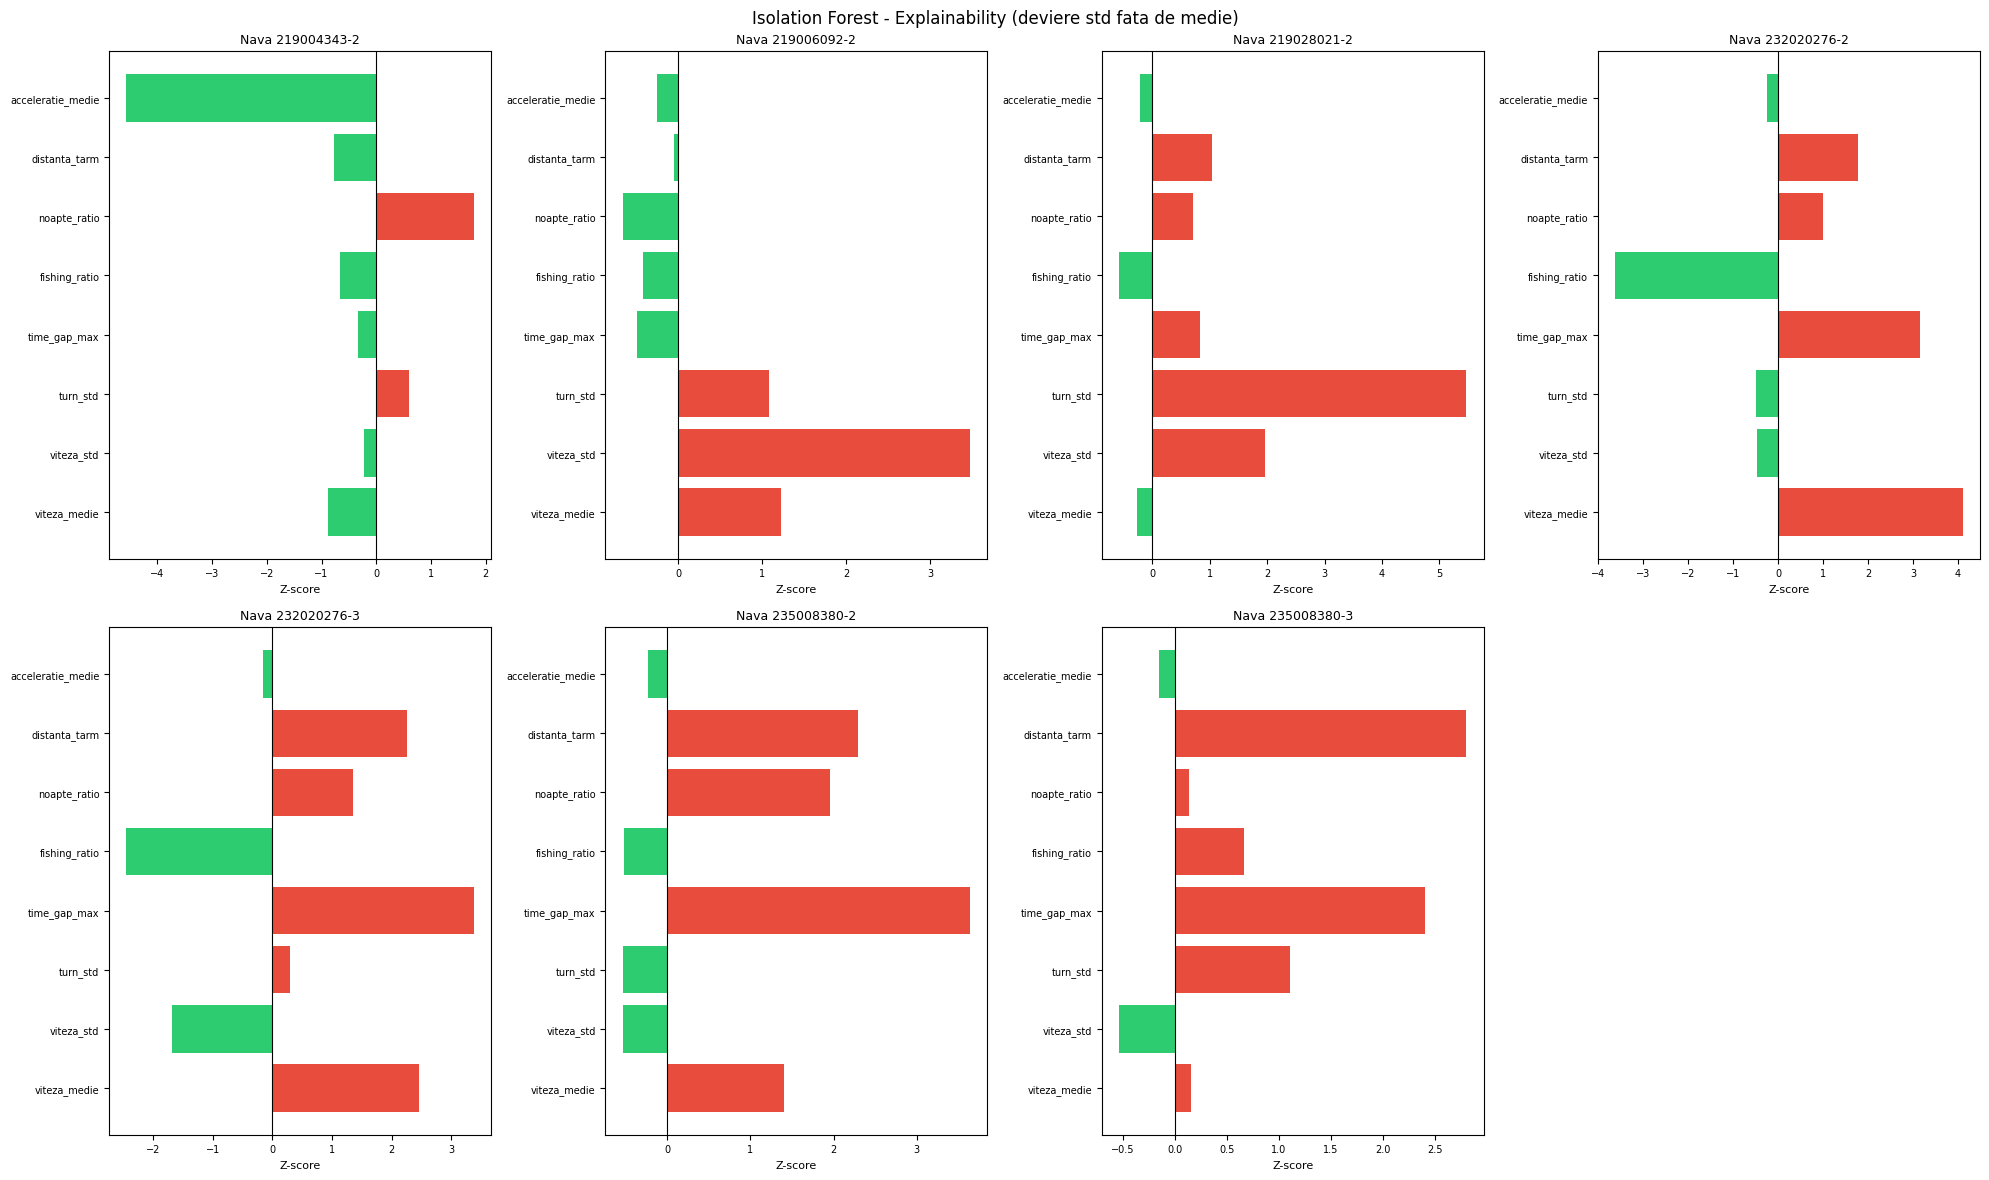

In [ ]:
import math

IF_FEATURES = ['viteza_medie', 'viteza_std', 'turn_std', 'time_gap_max',
               'fishing_ratio', 'noapte_ratio', 'distanta_tarm', 'acceleratie_medie']

scaler_if_exp = StandardScaler()
nave_features_rf_scaled = pd.DataFrame(
    scaler_if_exp.fit_transform(nave_features_rf[IF_FEATURES]),
    columns=IF_FEATURES,
    index=nave_features_rf['id']
)

nave_de_explicat = scor_df_rf[
    (scor_df_rf['scor_final'] >= 2) &
    (scor_df_rf['isolation_forest'] == 1)
]['id'].tolist()

fig, axes = plt.subplots(2, math.ceil(len(nave_de_explicat)/2), figsize=(20, 12))
axes = axes.flatten()

for idx, nava in enumerate(nave_de_explicat):
    valori = nave_features_rf_scaled.loc[nava]
    colors = ['#e74c3c' if v > 0 else '#2ecc71' for v in valori.values]
    axes[idx].barh(IF_FEATURES, valori.values, color=colors)
    axes[idx].axvline(0, color='black', linewidth=0.8)
    axes[idx].set_title(f'Nava {nava}', fontsize=9)
    axes[idx].set_xlabel('Z-score', fontsize=8)
    axes[idx].tick_params(labelsize=7)

for idx in range(len(nave_de_explicat), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle('Isolation Forest - Explainability (deviere std fata de medie)', fontsize=12)
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/if_explainability_rf.png", dpi=150, bbox_inches='tight')
plt.show()

Scor final RF

In [ ]:
scor_df_rf = pd.DataFrame({'id': df['id'].unique()})

scor_df_rf['loitering'] = scor_df_rf['id'].isin(nave_suspecte_loitering_rf).astype(int)
scor_df_rf['pescuit_noapte'] = scor_df_rf['id'].isin(nave_suspecte_noapte_rf).astype(int)
scor_df_rf['ais_gap'] = scor_df_rf['id'].isin(nave_suspecte_gap_rf).astype(int)
scor_df_rf['isolation_forest'] = scor_df_rf['id'].isin(nave_anomalii_rf).astype(int)
scor_df_rf['scor_final'] = scor_df_rf[['loitering', 'pescuit_noapte', 'ais_gap', 'isolation_forest']].sum(axis=1)

print("Distributia scorurilor finale RF:")
print(scor_df_rf['scor_final'].value_counts().sort_index())
print(f"\nNave normale (scor 0): {(scor_df_rf['scor_final']==0).sum()}")
print(f"Nave suspecte (scor 1): {(scor_df_rf['scor_final']==1).sum()}")
print(f"Nave suspecte (scor 2): {(scor_df_rf['scor_final']==2).sum()}")
print(f"Nave foarte suspecte (scor 3+): {(scor_df_rf['scor_final']>=3).sum()}")

scor_df_rf.to_csv(f"{RESULTS_DIR}/scor_final_iuu_rf.csv", index=False)
print("\nRezultate RF salvate!")

Distributia scorurilor finale RF:
scor_final
0    79
1    35
2     7
3     2
Name: count, dtype: int64

Nave normale (scor 0): 79
Nave suspecte (scor 1): 35
Nave suspecte (scor 2): 7
Nave foarte suspecte (scor 3+): 2

Rezultate RF salvate!


Vizualizare RF

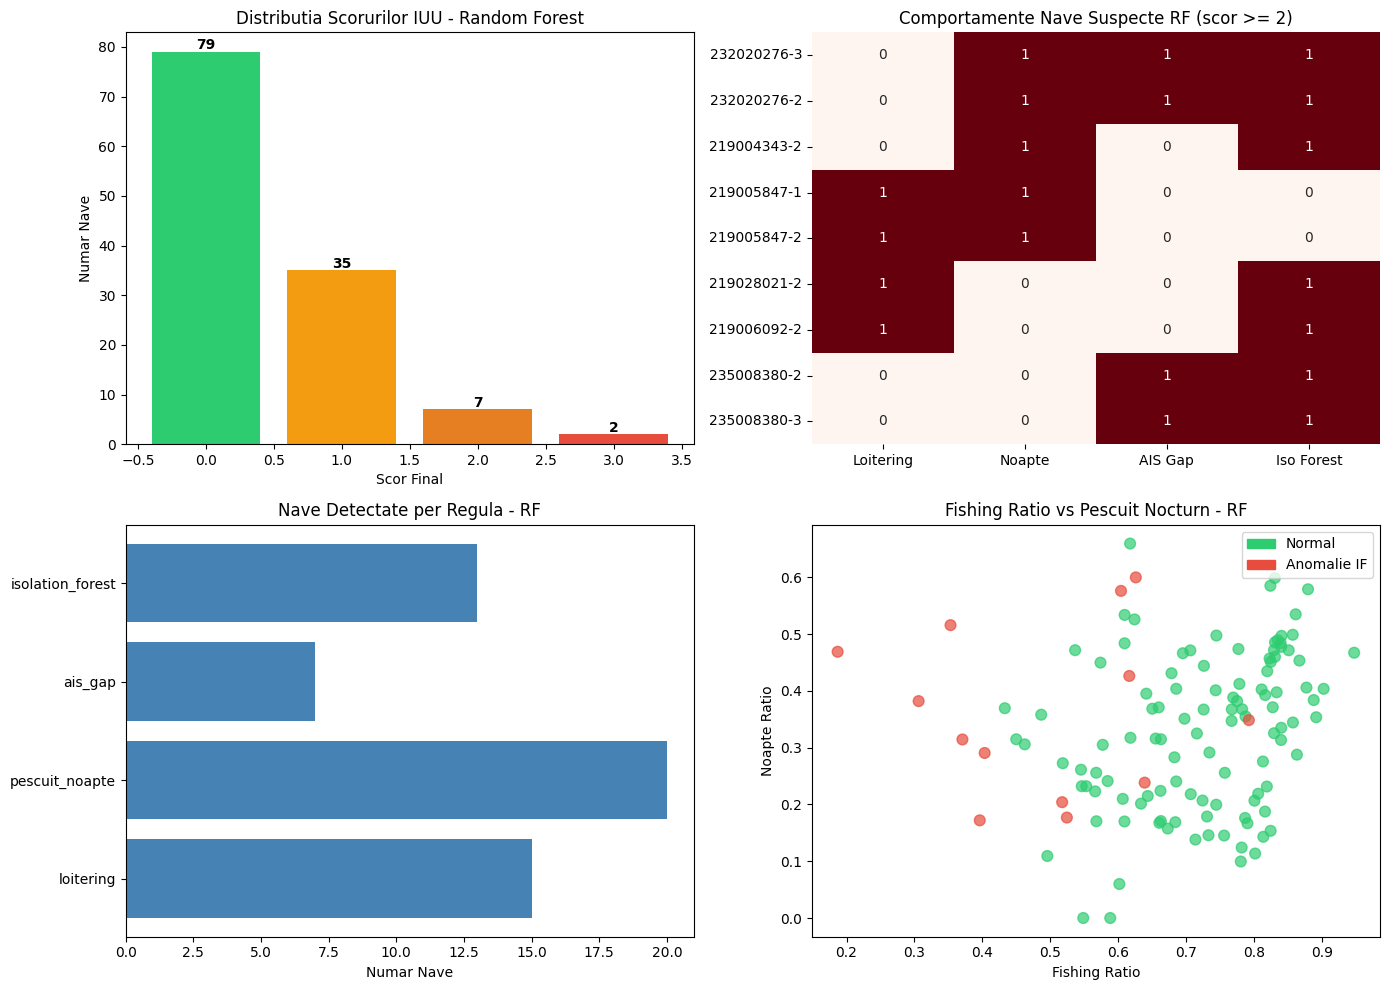

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

#distributia scorurilor finale RF
scor_counts_rf = scor_df_rf['scor_final'].value_counts().sort_index()
colors = ['#2ecc71', '#f39c12', '#e67e22', '#e74c3c']
axes[0, 0].bar(scor_counts_rf.index, scor_counts_rf.values, color=colors[:len(scor_counts_rf)])
axes[0, 0].set_title('Distributia Scorurilor IUU - Random Forest')
axes[0, 0].set_xlabel('Scor Final')
axes[0, 0].set_ylabel('Numar Nave')
for i, v in zip(scor_counts_rf.index, scor_counts_rf.values):
    axes[0, 0].text(i, v + 0.5, str(v), ha='center', fontweight='bold')

#heatmap nave suspecte RF
top_nave_rf = scor_df_rf[scor_df_rf['scor_final'] >= 2].sort_values('scor_final', ascending=False)
heatmap_data_rf = top_nave_rf.set_index('id')[['loitering', 'pescuit_noapte', 'ais_gap', 'isolation_forest']]
sns.heatmap(heatmap_data_rf, annot=True, cmap='Reds', ax=axes[0, 1], cbar=False,
            xticklabels=['Loitering', 'Noapte', 'AIS Gap', 'Iso Forest'])
axes[0, 1].set_title('Comportamente Nave Suspecte RF (scor >= 2)')
axes[0, 1].set_ylabel('')

#contributia fiecarei reguli RF
reguli_rf = ['loitering', 'pescuit_noapte', 'ais_gap', 'isolation_forest']
contributii_rf = scor_df_rf[reguli_rf].sum()
axes[1, 0].barh(contributii_rf.index, contributii_rf.values, color='steelblue')
axes[1, 0].set_title('Nave Detectate per Regula - RF')
axes[1, 0].set_xlabel('Numar Nave')

#scatter fishing ratio vs noapte ratio RF
axes[1, 1].scatter(nave_features_rf['fishing_ratio'], nave_features_rf['noapte_ratio'],
                   c=nave_features_rf['anomalie'].map({1: '#2ecc71', -1: '#e74c3c'}),
                   alpha=0.7, s=60)
axes[1, 1].set_title('Fishing Ratio vs Pescuit Nocturn - RF')
axes[1, 1].set_xlabel('Fishing Ratio')
axes[1, 1].set_ylabel('Noapte Ratio')
from matplotlib.patches import Patch
axes[1, 1].legend(handles=[Patch(color='#2ecc71', label='Normal'),
                             Patch(color='#e74c3c', label='Anomalie IF')])

plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/vizualizare_iuu_rf.png", dpi=150)
plt.show()

Compratie final Boss NN RF

6369/6369 ━━━━━━━━━━━━━━━━━━━━ 36s 6ms/step


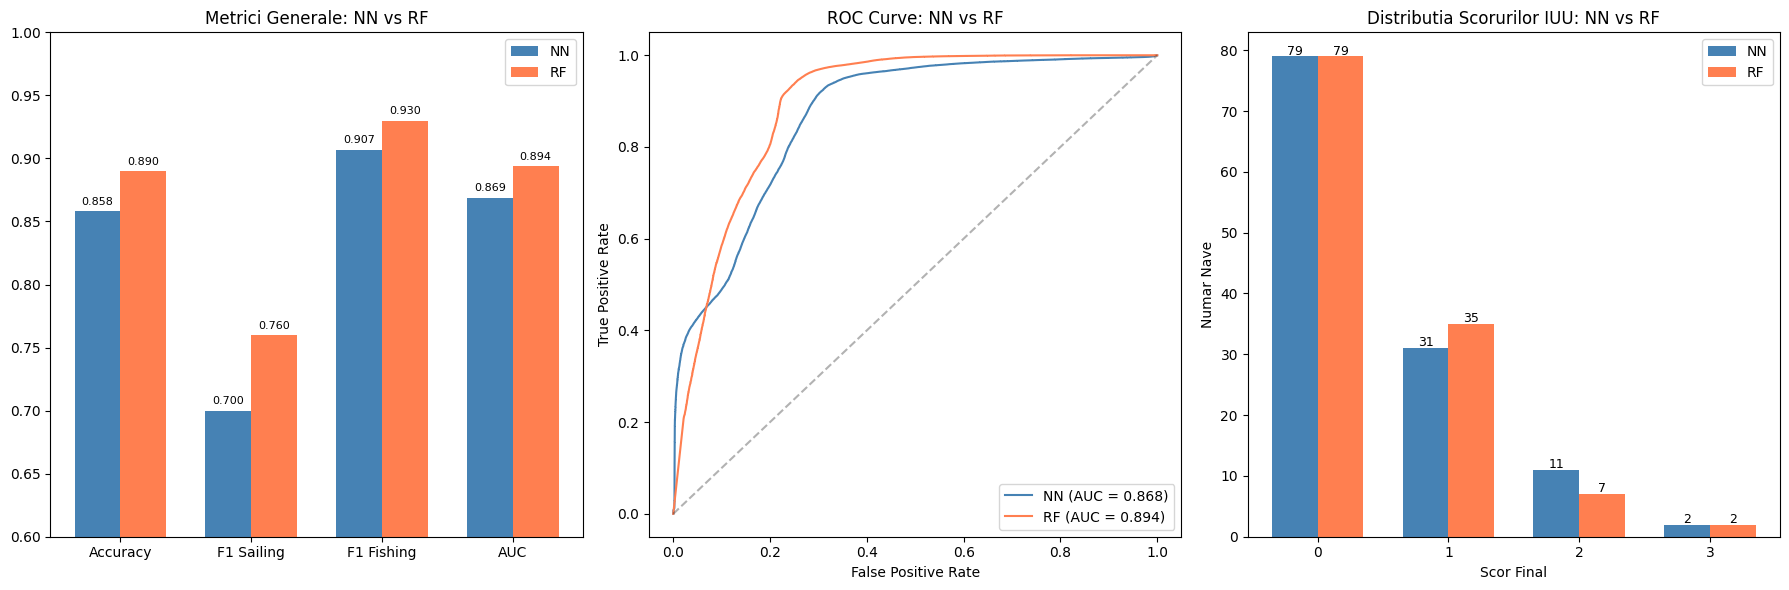

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1. AUC comparatie
metrici = ['Accuracy', 'F1 Sailing', 'F1 Fishing', 'AUC']
nn_vals = [0.858, 0.700, 0.907, 0.869]
rf_vals = [0.890, 0.760, 0.930, 0.894]

width = 0.35
x = range(len(metrici))
axes[0].bar([i - width/2 for i in x], nn_vals, width, label='NN', color='steelblue')
axes[0].bar([i + width/2 for i in x], rf_vals, width, label='RF', color='coral')
axes[0].set_title('Metrici Generale: NN vs RF')
axes[0].set_xticks(x)
axes[0].set_xticklabels(metrici)
axes[0].set_ylim(0.6, 1.0)
axes[0].legend()
for i, (v1, v2) in enumerate(zip(nn_vals, rf_vals)):
    axes[0].text(i - width/2, v1 + 0.005, f'{v1:.3f}', ha='center', fontsize=8)
    axes[0].text(i + width/2, v2 + 0.005, f'{v2:.3f}', ha='center', fontsize=8)

# 2. ROC Curve ambele
from sklearn.metrics import roc_curve, auc
fpr_nn, tpr_nn, _ = roc_curve(y_test, model.predict(X_test_scaled).flatten())
fpr_rf, tpr_rf, _ = roc_curve(y_test_rf, y_proba_rf_new)
axes[1].plot(fpr_nn, tpr_nn, color='steelblue', label=f'NN (AUC = 0.868)')
axes[1].plot(fpr_rf, tpr_rf, color='coral', label=f'RF (AUC = 0.894)')
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.3)
axes[1].set_title('ROC Curve: NN vs RF')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend()

# 3. Distributie scoruri IUU
x2 = [0, 1, 2, 3]
nn_counts = [scor_df['scor_final'].value_counts().sort_index().get(i, 0) for i in x2]
rf_counts = [scor_df_rf['scor_final'].value_counts().sort_index().get(i, 0) for i in x2]
axes[2].bar([i - width/2 for i in x2], nn_counts, width, label='NN', color='steelblue')
axes[2].bar([i + width/2 for i in x2], rf_counts, width, label='RF', color='coral')
axes[2].set_title('Distributia Scorurilor IUU: NN vs RF')
axes[2].set_xlabel('Scor Final')
axes[2].set_ylabel('Numar Nave')
axes[2].legend()
axes[2].set_xticks(x2)
for i, (v1, v2) in enumerate(zip(nn_counts, rf_counts)):
    axes[2].text(i - width/2, v1 + 0.3, str(v1), ha='center', fontsize=9)
    axes[2].text(i + width/2, v2 + 0.3, str(v2), ha='center', fontsize=9)

plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/comparatie_nn_rf.png", dpi=150)
plt.show()